# 03 - Area of the segmented pores and grains (Challenge task 3)

Using the objects from notebook 02, this notebook computes:
1. **Image scale**: how the two images relate, so their measurements can be compared.
2. **Phase areas**: total area of grains, pores and cement.
3. **Size distributions** of grains and pore bodies, with Folk & Ward (1957) statistics.
4. **Pore throats**: widths of the constrictions between pore bodies. Throats control permeability.
5. **Shape descriptors**: aspect ratio, circularity, solidity.

**Rules for measurement**
- Objects touching the image border are excluded from size and shape statistics, because only part of them is visible.
  They are kept for area fractions.
- Objects < 12 px area (equivalent diameter ~ 4 px) are below the reliable resolution and are excluded from shape statistics.
- Sizes are **apparent 2D section sizes**. A random section cuts most grains away from their equator, so thin-section
  diameters are systematically smaller than sieve diameters (Harrell & Eriksson, 1979, *J. Sed. Petrol.*). No
  stereological correction is applied; distributions are compared on the same basis.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
import figstyle; figstyle.install()   # larger text in all figures
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from scipy import stats
from segmentation import load_rgb, GRAIN, PORE, CEMENT, PHASE_NAMES
from objects import object_table, throat_table
from sizestats import folk_ward

plt.rcParams['figure.dpi'] = 90
IMAGES = {'small': '../Lamina_alunos2.png', 'large': '../Lamina_alunos_grande.png'}
imgs = {k: load_rgb(p) for k, p in IMAGES.items()}
phases = {k: np.load(f'../outputs/phases_{k}.npy') for k in IMAGES}
labels = {(k, n): np.load(f'../outputs/labels_{n}_{k}.npy') for k in IMAGES for n in ['grain', 'pore']}

PIXEL_UM_LARGE = None   # micrometres per pixel of the LARGE image. Set it when the scale is known.
MIN_AREA = 12

## 1. Putting both images in the same unit (Lpx)

**Why we calculate it and why it is important.** In one sentence: this section **makes sizes from the two images comparable**. It is useful for these reasons:

1. **The two images have different pixel sizes**, so the same grain has a different size in pixels in each image.
2. **It allows both images to be used together**: their size measurements can be compared and combined.
3. **It is a strong check of the whole method**: the same rock, photographed at two resolutions and segmented separately, gives the same result.
4. **It is not needed for percentages** (porosity, fractions), only for sizes.

| What this section gives | Why it is useful |
|---|---|
| how the two images relate (zoom 0.839) | sizes can be converted between them |
| the common unit Lpx | comparable sizes |
| same rock, same result | validation of the segmentation |

**The problem.** There is no scale bar, so every size in this notebook is measured in **pixels**. But a pixel does
not cover the same amount of rock in the two images: the small image is a **zoomed-in** view, so each of its pixels
covers less rock. The same grain therefore looks bigger (more pixels) in the small image than in the large one.
Comparing or combining pixel sizes from the two images directly would be wrong.

**The solution, in three steps:**
1. **Find how the two images relate:** where the small image sits inside the large one, and how much it is zoomed.
2. **Define a common unit, Lpx** (one pixel of the large image), and convert every size of the small image to it.
3. **Check that it works:** the same rock, measured in both images, must give the same result.

*Note:* percentages (porosity, grain and cement fractions) do **not** need this step, because the pixel size cancels
out in a ratio. The common unit is needed only to compare **sizes** (areas, diameters) between the two images.

### Step 1 - Find how the two images relate

**Idea.** If the small image is a zoomed-in part of the large one, then shrinking it by the right amount will make it
match a part of the large image exactly.

**How (template matching).** The code shrinks the small image by many factors (0.30, 0.31, ... 1.00). For each factor
it slides the shrunk image over the large image and computes a **match score** (normalised cross-correlation:
1 = identical, 0 = unrelated). It keeps the factor with the highest score, then refines it in steps of 0.001.

best scale = 0.839 (1 small px = 0.839 large px; magnification x1.192), NCC = 0.967, position in large image: x=214, y=429, size 717x477


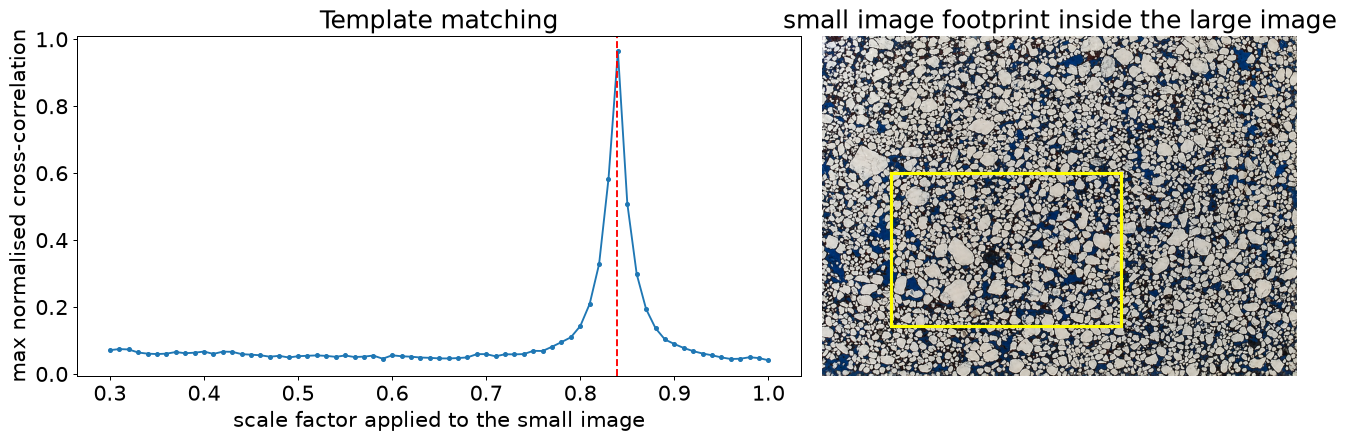

In [2]:
S = cv2.imread(IMAGES['small'], 0).astype(np.float32)
B = cv2.imread(IMAGES['large'], 0).astype(np.float32)

def match(scale):
    t = cv2.resize(S, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    r = cv2.matchTemplate(B, t, cv2.TM_CCOEFF_NORMED)
    _, mx, _, loc = cv2.minMaxLoc(r)
    return mx, loc, t.shape

coarse = np.arange(0.30, 1.001, 0.01)
ncc = [match(s)[0] for s in coarse]
fine = np.arange(0.825, 0.855, 0.001)
ncc_f = [match(s)[0] for s in fine]
SCALE = float(fine[int(np.argmax(ncc_f))])
best_ncc, (x0, y0), (h, w) = match(SCALE)
print(f'best scale = {SCALE:.3f} (1 small px = {SCALE:.3f} large px; magnification x{1/SCALE:.3f}), '
      f'NCC = {best_ncc:.3f}, position in large image: x={x0}, y={y0}, size {w}x{h}')

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(coarse, ncc, '.-'); ax[0].axvline(SCALE, color='r', ls='--')
ax[0].set_xlabel('scale factor applied to the small image'); ax[0].set_ylabel('max normalised cross-correlation')
ax[0].set_title('Template matching')
ax[1].imshow(imgs['large']); ax[1].add_patch(plt.Rectangle((x0, y0), w, h, fill=False, ec='yellow', lw=2.5))
ax[1].set_title('small image footprint inside the large image'); ax[1].axis('off')
plt.tight_layout(); plt.show()

**Reading the result.**
- **Left:** the match score is ~ 0.05 (no match) for almost every factor, then jumps to **0.97 at 0.839**. So the
  small image really is a part of the large image, shrunk by 0.839.
- **Right:** the yellow box is where the small image sits inside the large one.
- **Meaning of 0.839:** 1 pixel of the small image = 0.839 pixels of the large image. Equivalently, the small image
  is the large one magnified x1.19 (= 1 / 0.839).

### Step 2 - Define the common unit: Lpx

**Lpx = one pixel of the Large image.** It is our unit of length until the real pixel size (in micrometres) is known.

**Example.** One real grain measures 26.6 px across in the small image and 22.2 px in the large image.
22.2 / 26.6 = 0.84, the factor found in step 1. In Lpx it is 22.2 Lpx in both images.

**Conversion rules**
| Measured in | Lengths (diameter, perimeter) | Areas |
|---|---|---|
| large image | x 1 (already in Lpx) | x 1 (Lpx^2) |
| small image | x 0.839 | x 0.839^2 = x 0.704 (Lpx^2) |

Areas use the factor squared because an area is a length x a length.

**Real units.** If the pixel size of the large image becomes known (e.g. 5 micrometres per pixel), set
`PIXEL_UM_LARGE = 5` in the first cell: every Lpx then becomes micrometres and every Lpx^2 square micrometres.

The next cell stores the conversion factors used in the rest of the notebook (`LEN`) and the unit name (`UNIT`).

In [3]:
LEN = {'small': SCALE, 'large': 1.0}          # length conversion: image pixels -> Lpx
UNIT = 'Lpx'
if PIXEL_UM_LARGE:                              # optional: real units
    LEN = {k: v * PIXEL_UM_LARGE for k, v in LEN.items()}; UNIT = 'um'
print(f'1 small-image px = {LEN["small"]:.3f} {UNIT};  1 large-image px = {LEN["large"]:.3f} {UNIT}')

1 small-image px = 0.839 Lpx;  1 large-image px = 1.000 Lpx


### Step 3 - Check that it works

**Idea.** The small image and the box found in step 1 show the **same rock**, photographed at two resolutions and
segmented separately (notebook 01). If the segmentation is reliable, both must give the same grain, pore and cement
percentages.

The table compares three regions:
- **small image (full)**: the zoomed-in photo;
- **large image, same footprint**: only the yellow box of step 1 (same rock, lower resolution);
- **large image (full)**: the whole large photo (about 4x more rock), for reference.

In [4]:
ov = phases['large'][y0:y0 + h, x0:x0 + w]      # the yellow box of step 1
rows = []
for nm, ph in [('small image (full)', phases['small']), ('large image, same footprint', ov), ('large image (full)', phases['large'])]:
    rows.append({'region': nm, **{f'{PHASE_NAMES[c]} %': 100 * (ph == c).mean() for c in (GRAIN, PORE, CEMENT)}})
pd.DataFrame(rows).set_index('region').round(2)

,grain %,pore %,cement %
region,,,
small image (full),57.77,18.99,23.24
"large image, same footprint",57.49,19.24,23.27
large image (full),57.09,18.57,24.34


**Reading the table.**
- **Rows 1 and 2** (same rock, two images): they agree within **0.3 points** (grain 57.8 vs 57.5 %, pore 19.0 vs 19.2 %).
  The two images are correctly related, and the segmentation does not depend on the image resolution.
- **Row 3** (whole large image) differs slightly (pore 18.6 %, cement 24.3 %) because it contains more, different rock.
  That is natural variation from place to place (studied in notebook 04), not an error.

From here on, all sizes are reported in **Lpx**, so the two images can be compared directly.

## 2. Phase areas (total)

**Why we calculate it and why it is important.** In one sentence: this section **gives the total area of pores, grains and cement** in each image. It is useful for these reasons:

1. **It completes Task 1** with areas in the common unit, not only percentages.
2. **It links the percentages of notebook 01 to areas** that can be converted to real units once the pixel size is known.

| What this section gives | Why it is useful |
|---|---|
| area per phase (px and Lpx^2) | absolute amounts of each phase |
| fraction per phase (%) | the same as porosity and volume fractions |

The area of each phase is simply the **number of pixels** of that phase; the percentage is that number divided by the
total number of pixels in the image. The table gives, for each image and phase:
- **area_px**: number of pixels, in that image's own pixels;
- **area_Lpx2**: the same area in the common unit (small image x 0.704, large image unchanged);
- **fraction %**: share of the image (the same in both units, because it is a ratio).

In [5]:
rows = []
for k in IMAGES:
    ph = phases[k]; px_area = LEN[k] ** 2
    for c in (GRAIN, PORE, CEMENT):
        n = int((ph == c).sum())
        rows.append({'image': k, 'phase': PHASE_NAMES[c], 'area_px': n, f'area_{UNIT}2': n * px_area,
                     'fraction %': 100 * n / ph.size})
area_tab = pd.DataFrame(rows).set_index(['image', 'phase']).round(2)
area_tab

area_px  area_Lpx2  fraction %
image phase                                 
small grain    281034  197825.73       57.77
      pore      92402   65043.71       18.99
      cement   113059   79584.60       23.24
large grain    897686  897686.00       57.09
      pore     292003  292003.00       18.57
      cement   382713  382713.00       24.34

## 3. Per-object size distributions

**Why we calculate it and why it is important.** In one sentence: this section **measures the size of every grain and every pore body**: Challenge 3. It is useful for these reasons:

1. **It answers Challenge 3** (area of each segmented pore and grain).
2. **Grain size and sorting are basic descriptors of a sandstone**, and control porosity and permeability.
3. **It shows how the pore space is organised**: many small pores or a few large ones that hold most of the porosity.
4. **It checks both images agree**, confirming the measurements.

| What this section gives | Why it is useful |
|---|---|
| size of every object | Challenge 3 |
| size distributions and Folk & Ward statistics | grain size and sorting of the rock |
| where the porosity is | whether a few large pores dominate |

**What we do.** Section 2 gave one number per phase: how much of the image is grain, pore or cement. Here we
measure the **size of every single grain and every single pore body** (the objects cut out in notebook 02), then
look at how those sizes are **distributed**: how many are small, how many are large.

**Why.** The total area says *how much* pore space there is. It does not say *what it is made of*: many small pores
or a few large ones, uniform grains or a mix of sizes. That is what this section answers, and it is the core of
Challenge 3 (the area of **each** segmented pore and grain):
- **typical grain and pore size** (median equivalent diameter);
- **sorting**: how similar the grain sizes are, measured with the standard Folk & Ward (1957) statistics used in
  sedimentology;
- **where the porosity is**: whether most of the pore area sits in a few large pores. This matters for fluid flow in
  a reservoir.

**How.**
1. Take every grain and pore body from the label images of notebook 02.
2. For each object, measure its **area** and its **equivalent diameter** (the diameter of a circle with the same
   area), which turns an irregular shape into one "size" number. Perimeter, length and width are also recorded
   (used in section 5).
3. Convert the sizes to the common unit (Lpx, section 1) so both images can be compared.
4. **Leave out** objects that touch the image border (only part of them is visible, so their size would be wrong) and
   tiny objects of 12 px or less (too small to measure reliably).
5. Show the distributions:
   - a **histogram**: how many objects of each size;
   - a **cumulative curve**: what fraction of objects is smaller than a given size;
   - a **"where is the porosity?" curve**: the share of the total pore area held by pores larger than a given size.
6. Check that the small and large images give the same distributions (KS test), then compute the Folk & Ward
   statistics.

Note: these are **2D sizes** measured on a flat cut through the rock. A cut rarely passes through the middle of a
grain, so thin-section sizes are a little smaller than the true 3D sizes (Harrell & Eriksson, 1979).

### Step 1 - Measure every object

**What.** One row per grain and per pore body with its size and shape (area, equivalent diameter, perimeter, long and
short axes, aspect ratio, circularity, solidity), converted to Lpx.

**How.** `object_table()` (in `src/objects.py`) measures each labelled object of notebook 02. Sizes of the small image
are multiplied by the Lpx factors of section 1 (lengths x 0.839, areas x 0.704). Objects touching the border or of 12
px or less are left out of the statistics.

In [6]:
tabs = []
for (k, n), L in labels.items():
    t = object_table(L, n); t.insert(0, 'image', k)
    s = LEN[k]
    t['area_u'] = t['area'] * s ** 2
    for c in ['perimeter', 'eq_diameter', 'major_axis_length', 'minor_axis_length']:
        t[c + '_u'] = t[c] * s
    tabs.append(t)
objs = pd.concat(tabs, ignore_index=True)
valid = objs[~objs.on_border & (objs.area >= MIN_AREA)].copy()
print(f'objects: {len(objs)}, used for statistics: {len(valid)}')
valid.groupby(['image', 'phase'])[['area_u', 'eq_diameter_u', 'aspect_ratio', 'circularity', 'solidity']] \
     .describe(percentiles=[.5]).T.round(2)

objects: 6699, used for statistics: 6317


image                  large             small         
phase                  grain     pore    grain     pore
area_u        count  3565.00  1676.00   710.00   366.00
              mean    238.36   164.90   254.30   164.82
              std     329.80   213.42   391.19   201.25
              min      17.00    15.00    10.56    14.08
              50%     149.00    99.00   141.49    93.27
              max    8107.00  2849.00  5293.49  1662.66
eq_diameter_u count  3565.00  1676.00   710.00   366.00
              mean     15.44    12.97    15.61    12.84
              std       8.08     6.47     8.97     6.72
              min       4.65     4.37     3.67     4.23
              50%      13.77    11.23    13.42    10.90
              max     101.60    60.23    82.10    46.01
aspect_ratio  count  3565.00  1676.00   710.00   366.00
              mean      1.52     1.84     1.52     1.82
              std       0.38     0.60     0.38     0.56
              min       1.00     1.01     1.01     1.02
              50%       1.43     1.69     1.43     1.67
              max       4.28     5.16     3.54     4.38
circularity   count  3565.00  1676.00   710.00   366.00
              mean      0.82     0.70     0.82     0.70
              std       0.13     0.17     0.12     0.17
              min       0.26     0.22     0.23     0.29
              50%       0.85     0.72     0.85     0.71
              max       1.08     1.05     1.06     1.01
solidity      count  3565.00  1676.00   710.00   366.00
              mean      0.91     0.85     0.92     0.85
              std       0.05     0.09     0.04     0.09
              min       0.49     0.48     0.72     0.58
              50%       0.93     0.88     0.93     0.87
              max       1.00     1.00     1.00     1.00

**Reading the table.** Columns = the four groups (large/small image x grain/pore). For each measurement:
**count** = number of objects, **mean** = average, **std** = spread, **min** / **max** = extremes, **50 %** = median
(half the objects are below it; more reliable than the mean, which a few huge grains pull up).

| Measurement | Meaning | Grains (large, median) | Pores (large, median) |
|---|---|---|---|
| **area_u** | area in Lpx^2 | 149 | 99 |
| **eq_diameter_u** | diameter of a circle with the same area, in Lpx | 13.8 | 11.2 |
| **aspect_ratio** | length / width (1 = round) | 1.43 | 1.69 |
| **circularity** | 4 pi area / perimeter^2 (1 = circle) | 0.85 | 0.72 |
| **solidity** | area / convex-hull area (1 = no indentations) | 0.93 | 0.88 |

Grains are compact and convex; pores are smaller, more elongated and irregular (they fill the spaces between
grains). The small and large columns are almost identical, so the Lpx conversion works.

### Step 2 - Plot the size distributions

**Why.** A table of statistics hides the *shape* of the distribution: is it narrow or wide, symmetric or skewed?
And for a reservoir: is the pore space made of many small pores or a few large ones?

**What (three plots).**
- **Left, histogram:** how many objects of each size. The size axis is logarithmic, the standard for grain sizes.
- **Centre, cumulative curve:** the fraction of objects smaller than a given size.
- **Right, "where is the porosity?":** pores are sorted from largest to smallest and their areas are added up. The
  curve gives the share of the total pore area held by pores of at least that size.

Solid lines = large image, dashed = small image.

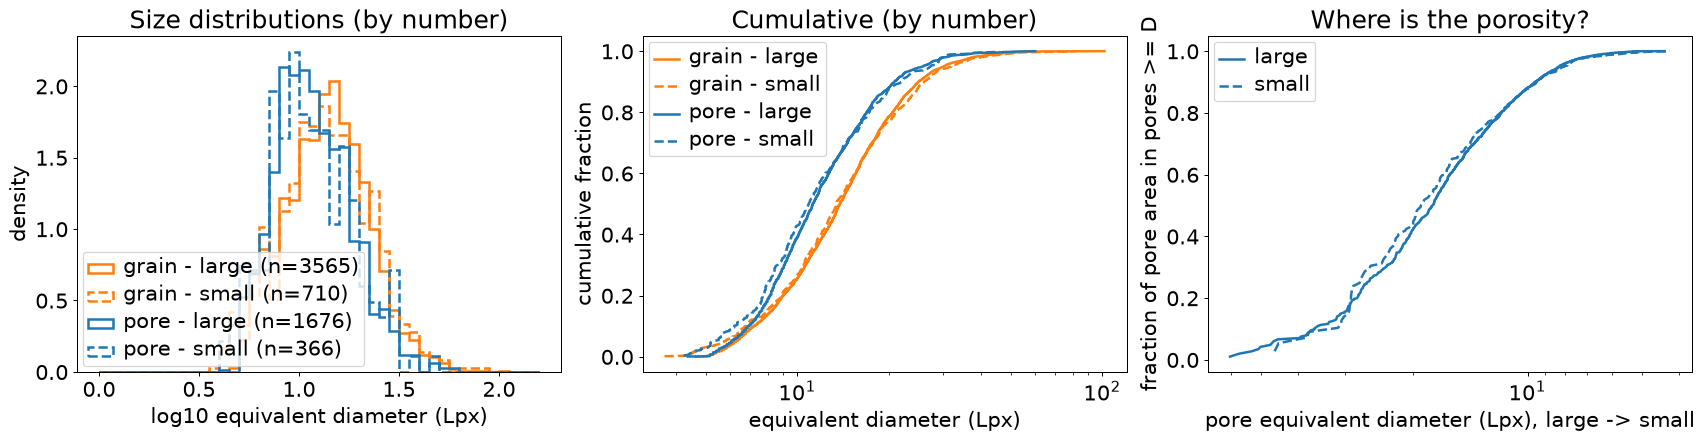

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
bins = np.linspace(0, 2.2, 45)
for n, c in [('grain', 'tab:orange'), ('pore', 'tab:blue')]:
    for k, ls in [('large', '-'), ('small', '--')]:
        d = valid.query('image == @k and phase == @n').eq_diameter_u
        ax[0].hist(np.log10(d), bins, histtype='step', lw=2, ls=ls, color=c, density=True, label=f'{n} - {k} (n={len(d)})')
        x = np.sort(d); ax[1].plot(x, np.arange(1, len(x) + 1) / len(x), ls=ls, color=c, lw=2, label=f'{n} - {k}')
ax[0].set_xlabel(f'log10 equivalent diameter ({UNIT})'); ax[0].set_ylabel('density'); ax[0].legend(); ax[0].set_title('Size distributions (by number)')
ax[1].set_xscale('log'); ax[1].set_xlabel(f'equivalent diameter ({UNIT})'); ax[1].set_ylabel('cumulative fraction'); ax[1].legend(); ax[1].set_title('Cumulative (by number)')

# cumulative POROSITY carried by pores larger than D (reservoir view)
for k, ls in [('large', '-'), ('small', '--')]:
    p = valid.query('image == @k and phase == "pore"').sort_values('eq_diameter_u', ascending=False)
    ax[2].plot(p.eq_diameter_u, p.area_u.cumsum() / p.area_u.sum(), ls=ls, lw=2, color='tab:blue', label=k)
ax[2].set_xscale('log'); ax[2].invert_xaxis(); ax[2].set_xlabel(f'pore equivalent diameter ({UNIT}), large -> small')
ax[2].set_ylabel('fraction of pore area in pores >= D'); ax[2].set_title('Where is the porosity?'); ax[2].legend()
plt.tight_layout(); plt.show()

**Reading the plots.**
- **Left / centre:** grains (orange) are slightly larger than pores (blue); both are single-peaked and fairly narrow
  (80 % of grains are between 7 and 25 Lpx). Solid and dashed lines overlap: both images give the same sizes.
- **Right:** half of the pore area is in pores of 17.8 Lpx or more, although the median pore is only 11.2 Lpx. The
  largest 10 % of pores hold 38 % of the pore area: **a few large pores carry much of the porosity**.

### Step 3 - Check that both images give the same distributions

**Why.** The plots suggest the two images agree; this makes it a formal test. If the Lpx conversion and the
segmentation are right, the same rock must give the same size distribution in both images.

**How.** The two-sample **Kolmogorov-Smirnov (KS) test** compares the two sets of diameters. The **KS statistic** is
the largest gap between their cumulative curves (0 = identical). The **p-value** is the chance of a gap that large if
both come from the same distribution: p > 0.05 means no detectable difference.

In [8]:
rows = []
for n in ['grain', 'pore']:
    a = valid.query('image == "small" and phase == @n').eq_diameter_u
    b = valid.query('image == "large" and phase == @n').eq_diameter_u
    ks = stats.ks_2samp(a, b)
    rows.append({'phase': n, 'median small': a.median(), 'median large': b.median(),
                 'KS statistic': ks.statistic, 'p-value': ks.pvalue})
pd.DataFrame(rows).set_index('phase').round(3)

,median small,median large,KS statistic,p-value
phase,,,,
grain,13.422,13.774,0.032,0.583
pore,10.897,11.227,0.058,0.251


**Reading the table.** Medians differ by less than 0.4 Lpx and both p-values are large (grains 0.58, pores 0.25):
**no detectable difference** between the two images. The size measurements do not depend on the image resolution.

### Step 4 - Folk & Ward statistics

**Why.** Sedimentologists describe grain-size distributions with four standard numbers (Folk & Ward, 1957). They make
the result comparable with sieve analyses and with the literature, and **sorting** is a key control on porosity and
permeability.

**What.**
| Statistic | Meaning |
|---|---|
| **mean** | average size |
| **sorting** | spread of sizes: small = similar sizes (well sorted), large = mixed (poorly sorted) |
| **skewness** | asymmetry: > 0 = tail of fine sizes, < 0 = tail of coarse sizes, ~ 0 = symmetric |
| **kurtosis** | peakedness: ~ 1 = normal, > 1 = sharper peak |

**How.** Sizes are converted to the **phi scale**, phi = -log2(D), used in sedimentology (each +1 phi = half the size).
The statistics are computed from percentiles of phi (5, 16, 25, 50, 75, 84, 95 %).
- Sorting, skewness and kurtosis do not depend on the unit. The **mean** does: it is in phi of Lpx and becomes a real
  grain-size class only once the pixel size is known.
- Two weightings: *by number* (each object counts once, the usual image-analysis convention) and *by area* (large
  grains count more, closer to a sieve analysis by weight).

In [9]:
rows = []
for (k, n), g in valid.groupby(['image', 'phase']):
    for wname, wt in [('number', None), ('area', g.area_u)]:
        fw = folk_ward(g.eq_diameter_u, wt)
        rows.append({'image': k, 'phase': n, 'weighting': wname, 'n': len(g), **fw})
fw_tab = pd.DataFrame(rows).set_index(['image', 'phase', 'weighting'])
fw_tab.round(3)

n  mean_phi  median_phi  sorting_phi  skewness  \
image phase weighting                                                      
large grain number     3565    -3.767      -3.784        0.690     0.018   
            area       3565    -4.475      -4.448        0.732    -0.060   
      pore  number     1676    -3.535      -3.489        0.620    -0.133   
            area       1676    -4.163      -4.150        0.742    -0.072   
small grain number      710    -3.765      -3.747        0.754    -0.025   
            area        710    -4.590      -4.584        0.827    -0.063   
      pore  number      366    -3.522      -3.446        0.694    -0.148   
            area        366    -4.186      -4.242        0.718     0.078   

                       kurtosis           sorting_class  mean_D  
image phase weighting                                            
large grain number        0.999  moderately well sorted  13.618  
            area          1.038       moderately sorted  22.238  
      pore  number        0.974  moderately well sorted  11.590  
            area          0.982       moderately sorted  17.908  
small grain number        1.050       moderately sorted  13.599  
            area          1.074       moderately sorted  24.078  
      pore  number        0.994  moderately well sorted  11.484  
            area          0.912       moderately sorted  18.200

**Reading the table (grains, large image, by number).** Sorting **0.69 phi = moderately well sorted** (the border
between "moderately well" and "moderately"); skewness 0.02 = symmetric; kurtosis 1.00 = normal peak. The small image
gives the same class. Weighting by area gives larger mean sizes (large grains count more) and slightly wider
sorting, as expected.

## 4. Pore throats

**Why.** Fluids move from pore to pore through the narrow passages between them, the **throats**. The narrowest
passages control how easily fluid flows (permeability) and how hard it is for oil or gas to enter (capillary
pressure). In reservoir rocks throat size often matters more than pore size.

**Why we calculate it and why it is important.** In one sentence: this section **measures the narrow passages between pores**. It is useful for these reasons:

1. **Throats control flow**: permeability and the pressure needed for oil or gas to enter the pores depend on the narrowest passages, more than on pore size.
2. **It links the pore segmentation (notebook 02) to reservoir quality**: the cuts made there are the throats.
3. **It shows the limits of the images**: throats are close to the pixel size.

| What this section gives | Why it is useful |
|---|---|
| width of every throat | the flow-controlling passages |
| throat vs pore size | how constricted the pore network is |
| resolution caution | throat widths are an upper estimate |

**What.** The width of every throat, compared with the size of the pore bodies.

**How.** The throats are the cuts made between neighbouring pore bodies in notebook 02. At each cut, the widest point
of the contact is found on the pore-space distance map (distance to the nearest grain or cement). Throat width = 2 x
that distance.

**What the cell shows**
1. A printed line per image: number of throats, median throat width, median pore-body diameter and their ratio.
2. One histogram comparing the two sizes:

| Curve | What each value is | Colour / line |
|---|---|---|
| **throats** | width of one throat = 2 x the distance to the nearest grain or cement at the widest point of the contact between two pore bodies | blue solid = large image, orange dashed = small image |
| **pore bodies** | equivalent diameter of one pore body (diameter of a circle with the same area) | grey; solid = large, dashed = small |

**x axis: size in Lpx**, a throat width or a pore-body diameter, on the same axis so the two can be compared.
**y axis: density**, how common each size is. Each curve is scaled so the area under it is 1, which allows the curves
to be compared although there are fewer throats (565 in the large image) than pore bodies (1,676).

small  throats=  126  median throat width=3.36 Lpx  median pore-body diameter=10.90 Lpx  body/throat aspect ~ 3.2


large  throats=  565  median throat width=4.00 Lpx  median pore-body diameter=11.23 Lpx  body/throat aspect ~ 2.8


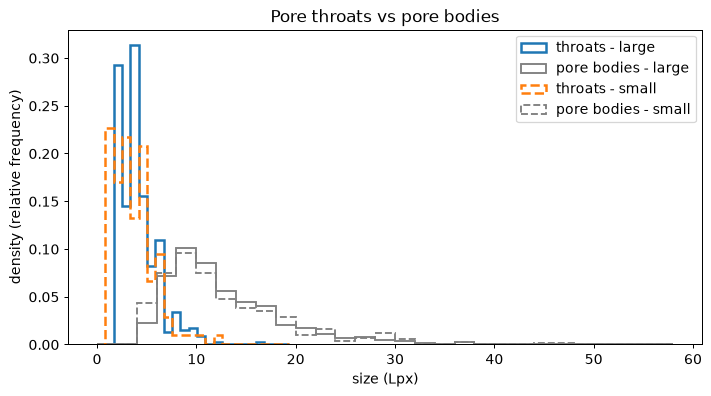

In [10]:
throats = {}
for k in IMAGES:
    t = throat_table(labels[(k, 'pore')], phases[k] == PORE)
    t['width_u'] = t['width'] * LEN[k]
    throats[k] = t
    pb = valid.query('image == @k and phase == "pore"').eq_diameter_u
    print(f'{k:6s} throats={len(t):5d}  median throat width={t.width_u.median():.2f} {UNIT}  '
          f'median pore-body diameter={pb.median():.2f} {UNIT}  body/throat aspect ~ {pb.median() / t.width_u.median():.1f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, ls in [('large', '-'), ('small', '--')]:
    ax.hist(throats[k].width_u, bins=np.arange(0, 20, 0.84), histtype='step', lw=2, ls=ls, density=True, label=f'throats - {k}')
    ax.hist(valid.query('image == @k and phase == "pore"').eq_diameter_u, bins=np.arange(0, 60, 2), histtype='step',
            lw=1.5, ls=ls, density=True, color='gray', label=f'pore bodies - {k}')
ax.set_xlabel(f'size ({UNIT})')
ax.set_ylabel('density (relative frequency)'); ax.legend(); ax.set_title('Pore throats vs pore bodies')
plt.tight_layout(); plt.show()

**Reading the result.**
- **Printed values:** large image, 565 throats with median width **4.0 Lpx**; median pore body **11.2 Lpx**, so pore
  bodies are ~ 2.8x wider than their throats (small image: 3.4 vs 10.9 Lpx, ratio 3.2).
- **Histogram:** the blue and orange throat curves are narrow and sit at small sizes (mostly 1-7 Lpx); the grey pore-body
  curves are much wider and further right (mostly 5-25 Lpx). Throats are the **narrow bottlenecks** between wide pores.
  Solid and dashed curves are close: both images agree.

**Caution.** 3-4 px is close to the image resolution. Throats narrower than ~ 2 px cannot be seen: the pores look
disconnected. These widths are therefore an **upper estimate**; higher magnification would be needed for real throat
sizes.

## 5. Shape descriptors

**Why we calculate it and why it is important.** In one sentence: this section **describes the shape of grains and pores** with simple, standard numbers. It is useful for these reasons:

1. **Grain shape records transport history**: rounded grains have travelled further.
2. **Pore shape reflects how grains and cement bound the pore space**.
3. **These descriptors are used later**: solidity flags merged grains (notebook 05), and they check the meaning of the Fourier indices.

| What this section gives | Why it is useful |
|---|---|
| aspect ratio, circularity, solidity | shape of every grain and pore |
| grains vs pores | compact grains, irregular pores |
| shape vs size | whether large objects have different shapes |

**Why.** Size alone does not describe the objects. Grain shape reflects transport and abrasion (rounded grains have
travelled further); pore shape reflects how the pore space is bounded by grains and cement.

**What (large image, interior objects).**
- **Top:** distributions of aspect ratio (elongation), circularity (closeness to a circle) and solidity (absence of
  indentations), grains vs pores.
- **Bottom:** circularity against size, to see whether small and large objects have different shapes.

**How.** The three descriptors are already in the table of step 1. Circularity uses the **Crofton perimeter**: the
simple pixel-count perimeter underestimates the perimeter of small rounded objects and gives circularity > 1.
Spearman's rho measures whether circularity rises or falls with size (-1 to +1; 0 = no relation).

**The three descriptors (x axes of the top plots)**

| Descriptor | Formula | Value 1 means | Lower / higher means |
|---|---|---|---|
| **aspect ratio** | length / width (long axis / short axis of the best-fitting ellipse) | as long as wide | higher = more elongated (2 = twice as long as wide) |
| **circularity** | 4 pi x area / perimeter^2 | a perfect circle | lower = more irregular or elongated outline |
| **solidity** | area / area of the convex hull (a rubber band stretched around the object) | no indentations (convex) | lower = more bays and concavities |

**y axis (top plots): density**, how common each value is. Each colour is scaled so that the total **area** of its bars
is 1 (bar height x bar width = share of objects in that bar). That is why the heights can exceed 1 when the bars are
narrow. The scaling allows grains (3,565) and pores (1,676) to be compared although there are twice as many grains.
Values beyond the plotted range are counted in the last bar. **Grey** = where the orange and blue bars overlap.

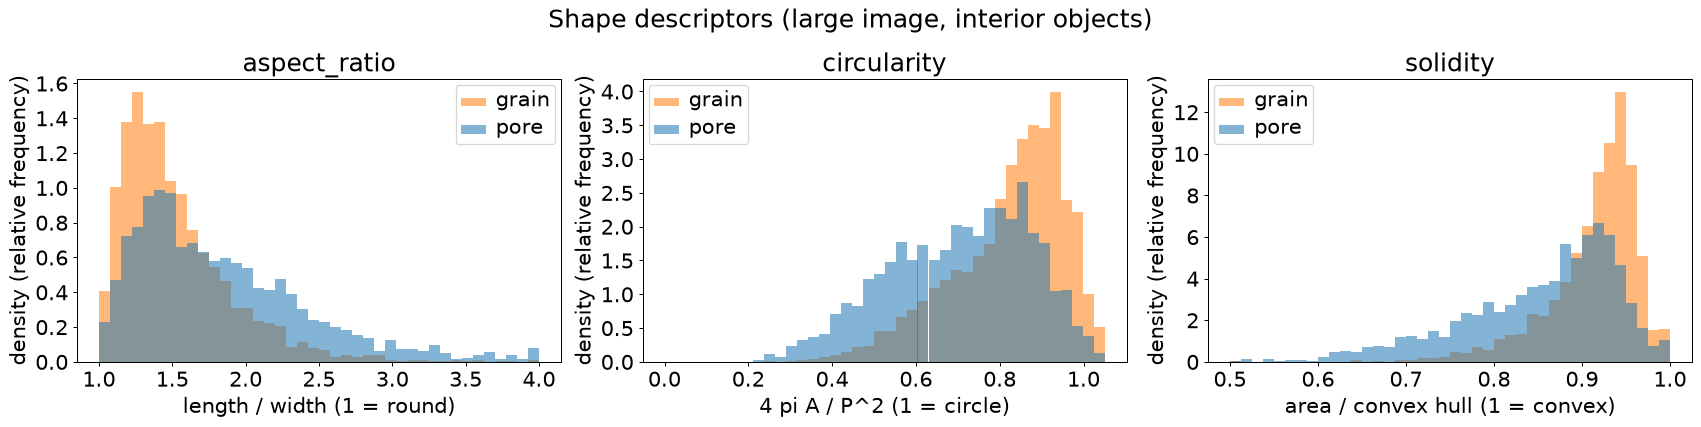

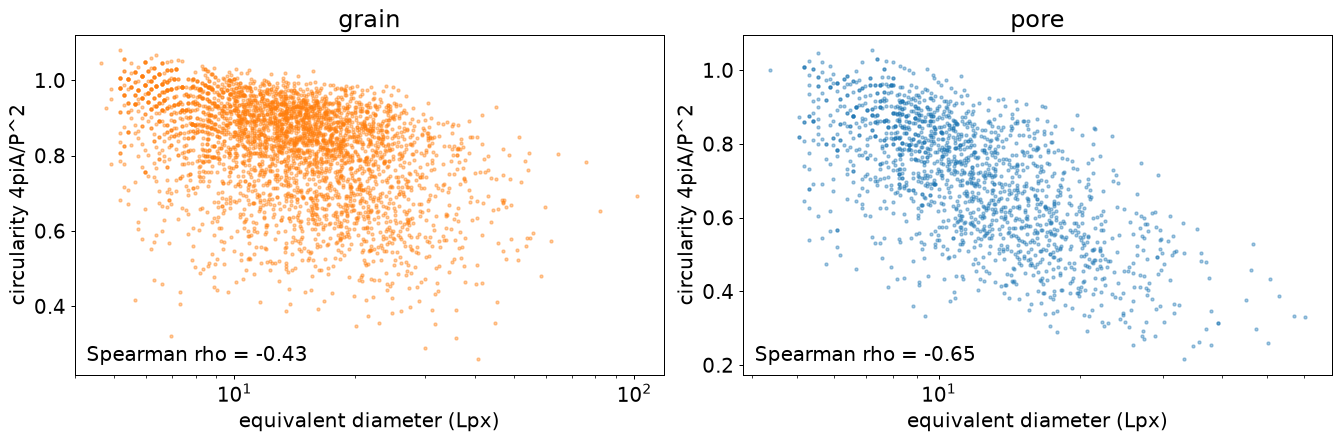

In [11]:
big = valid.query('image == "large"')
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for a, col, rng in zip(ax, ['aspect_ratio', 'circularity', 'solidity'], [(1, 4), (0, 1.05), (0.5, 1.0)]):
    for n, c in [('grain', 'tab:orange'), ('pore', 'tab:blue')]:
        a.hist(big.query('phase == @n')[col].clip(*rng), bins=40, range=rng, alpha=0.55, color=c, density=True, label=n)
    a.set_title(col); a.legend()
    a.set_xlabel({'aspect_ratio': 'length / width (1 = round)',
                  'circularity': '4 pi A / P^2 (1 = circle)',
                  'solidity': 'area / convex hull (1 = convex)'}[col])
    a.set_ylabel('density (relative frequency)')
plt.suptitle('Shape descriptors (large image, interior objects)'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, n, c in zip(ax, ['grain', 'pore'], ['tab:orange', 'tab:blue']):
    d = big.query('phase == @n')
    a.scatter(d.eq_diameter_u, d.circularity, s=6, alpha=0.4, color=c)
    a.set_xscale('log'); a.set_xlabel(f'equivalent diameter ({UNIT})'); a.set_ylabel('circularity 4piA/P^2'); a.set_title(n)
    rho = stats.spearmanr(d.eq_diameter_u, d.circularity)
    a.text(0.02, 0.04, f'Spearman rho = {rho.statistic:.2f}', transform=a.transAxes)
plt.tight_layout(); plt.show()

**Reading the plots.**
- **Top, how to read a histogram:** each bar shows how many objects (as a share) have that value. Where the orange
  bars (grains) and the blue bars (pores) sit tells how the two differ:
  - **aspect ratio:** grains are concentrated near 1-1.5 (compact); pores spread further right, to 2-3
    (elongated);
  - **circularity:** grains mostly 0.8-1.0 (close to a circle); pores spread lower, 0.5-0.8 (irregular);
  - **solidity:** grains mostly above 0.9 (convex); pores lower, 0.8-0.9 (with bays).

  Grains are compact, convex shapes; pores are elongated and concave. That is expected for the spaces between
  rounded grains.
- **Bottom:** each dot is one object, with its size (x) and circularity (y). Circularity decreases with size
  (Spearman rho = -0.43 for grains, -0.65 for pores): large objects have more irregular outlines. For grains, part of
  this comes from touching grains that were not fully separated.

## 6. Save

The tables are saved to `outputs/` for the next notebooks:
- `03_objects_scaled.csv`: every object with its measurements in Lpx (used by notebooks 04 and 05);
- `03_phase_areas.csv`: phase areas (section 2);
- `03_folk_ward.csv`: Folk & Ward statistics;
- `03_throats.csv`: throat widths;
- `03_registration.csv`: the scale factor and position of the small image inside the large one (section 1).

In [12]:
objs.to_csv('../outputs/03_objects_scaled.csv', index=False)
area_tab.to_csv('../outputs/03_phase_areas.csv')
fw_tab.to_csv('../outputs/03_folk_ward.csv')
pd.concat([t.assign(image=k) for k, t in throats.items()]).to_csv('../outputs/03_throats.csv', index=False)
pd.Series({'scale_small_to_large': SCALE, 'ncc': best_ncc, 'x0': x0, 'y0': y0, 'w': w, 'h': h}).to_csv('../outputs/03_registration.csv')
print('saved')

saved


## Findings

| Quantity | Large image | Small image (rescaled) |
|---|---|---|
| Grain / pore / cement area % | 57.1 / 18.6 / 24.3 | 57.8 / 19.0 / 23.2 |
| Median grain eq. diameter (Lpx) | 13.8 | 13.4 |
| Median pore-body eq. diameter (Lpx) | 11.2 | 10.9 |
| Median throat width (Lpx) | 4.0 | 3.4 |
| Grain sorting (Folk & Ward, by number) | 0.69 phi, moderately well sorted | 0.75 phi, moderately sorted |
| Grain skewness / kurtosis | 0.02 / 1.00 (symmetric, mesokurtic) | -0.03 / 1.05 |

- **The two images are the same rock at two magnifications**: the small image is a crop of the large one, resampled
  x1.19 (NCC = 0.97). In the overlap footprint the phase fractions measured independently in each image agree within
  0.3 %. After conversion to a common unit, the KS test cannot distinguish the size distributions (p = 0.58 for grains,
  0.25 for pores). This validates the segmentation and the object separation.
- **Grains** are moderately well sorted (sorting ~ 0.7 phi, on the border between *moderately well* and *moderately*),
  with a near-symmetric, mesokurtic log-normal distribution. Sorting is unit-free and can be quoted directly.
- **Porosity is concentrated in the large pores**: the largest 10 % of pore bodies hold 38 % of the pore area and the
  largest 20 % hold 55 %. Half the porosity sits in pores with D >= 17.8 Lpx, although the median pore is 11.2 Lpx.
- **Throats** are ~ 3x narrower than pore bodies (median 4.0 vs 11.2 Lpx). They are the permeability-controlling constrictions.
  Throat widths of 3-4 px are close to the image resolution, so they are an **upper estimate**: throats narrower than
  ~ 2 px are not resolved and appear as closed contacts.
- **Shape**: grains are compact and convex (median aspect ratio 1.43, circularity 0.85, solidity 0.93). Pores are
  elongated and concave (1.69, 0.72, 0.88), as expected for intergranular space bounded by convex grains.
  Median pore size is ~ 0.8 x the median grain size.
- Circularity uses the **Crofton perimeter**. The default pixel perimeter biased small objects to circularity > 1
  (15 % of objects); with Crofton only 3 % are marginally above 1 (digitisation noise).
- Limitations: apparent 2D sizes underestimate true 3D sizes (Harrell & Eriksson, 1979). Without a scale bar, absolute
  sizes and the Folk & Ward *mean* stay in pixel units (set `PIXEL_UM_LARGE` to convert).